## 1. Setup (Colab / Kaggle / local / Vast.ai)

In [1]:

import os
import re
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/oelaimar/NeuroVision-AI.git"

def sh(*cmd):
    subprocess.check_call(cmd)

# 1. Check whether the current directory is already inside the repo
cwd = Path.cwd().resolve()
root = None

for directory in [cwd, *cwd.parents]:
    if (directory / ".git").exists():
        root = directory
        break

# 2. If not, clone the repository
if root is None:
    if Path("/kaggle/working").exists():
        base_dir = Path("/kaggle/working")
    elif Path("/content").exists():
        base_dir = Path("/content")
    else:
        # Vast.ai or a local machine
        base_dir = cwd

    root = base_dir / "NeuroVision-AI"

    if not (root / ".git").exists():
        if root.exists():
            raise RuntimeError(
                f"{root} exists but is not a Git repository. "
                "Choose another clone directory or inspect this folder."
            )
        sh("git", "clone", REPO_URL, str(root))

# 3. Install requirements, keeping existing ML framework builds
requirements_file = root / "requirements.txt"

if requirements_file.exists():
    reqs = []

    for line in requirements_file.read_text().splitlines():
        line = line.strip()

        if not line or line.startswith(("#", "-")):
            continue

        name = re.split(r"[<>=!~\[;\s]", line, maxsplit=1)[0]
        name = name.lower().replace("_", "-")

        reqs.append(line)

    if reqs:
        sh(sys.executable, "-m", "pip", "install", *reqs)

# 4. Configure Python imports
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# 5. Display repository and current commit
commit = subprocess.check_output(
    ["git", "-C", str(root), "rev-parse", "--short", "HEAD"],
    text=True
).strip()

print("Repository:", root)
print("Commit:", commit)
print("Git repository detected successfully.")


Cloning into '/NeuroVision-AI'...


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 27.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 16.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 27.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 19.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 28.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 25.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 28.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 KB 25.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 KB 28.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 KB 29.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 20.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 KB 20.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Imports, config, dataset

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.balance import class_distribution
from src.config import Config
from src.dataset_download import ensure_dataset
from src.pipeline import DataSpec, build_augmenter, get_datasets, get_splits, get_test_ds
from src.repro import set_seed, start_run

cfg = Config()
set_seed(cfg)

RAW_DIR = cfg.data_dir
CLASSES = list(cfg.classes)
IMG_SIZE = cfg.img_size
BATCH_SIZE = cfg.batch_size
DATA_FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
DATA_SHA256 = ""

ensure_dataset(RAW_DIR, CLASSES, DATA_FILE_ID, DATA_SHA256)

spec = DataSpec(
    raw_dir=cfg.data_dir,
    classes=cfg.classes,
    val_split=cfg.val_frac,
    test_split=cfg.test_frac,
    target_size=cfg.img_size,
    cache_path=cfg.cache_path,
    manifest_path=cfg.manifest_path,
    seed=cfg.seed,
)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


2026-10-22 15:23:37.272248: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792682617.292473    2568 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792682617.298487    2568 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792682617.315040    2568 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792682617.315059    2568 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792682617.315062    2568 computation_placer.cc:177] computation placer alr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 KB 1.9 MB/s eta 0:00:00


Downloading...
From (original): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs
From (redirected): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs&confirm=t&uuid=fa63f25d-bde3-4387-8c4c-6a5f01697f05
To: /NeuroVision-AI/data/data.zip
100%|██████████| 156M/156M [00:11<00:00, 13.0MB/s] 


data.zip sha256: 50563c93d7e6cc5637b8fb3d559d41008cfe739c2b10cce485f1bade5ac35f3c
Dataset ready: data/raw
TensorFlow 2.19.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Check that every file is an image

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
non_image = [
    p for c in CLASSES for p in (Path(RAW_DIR) / c).rglob("*")
    if p.is_file() and p.suffix.lower() not in IMG_EXT
]
print(len(non_image))

0


## 4. Load data and class balance

Successfully loaded: 1621 images
Skipped: 0 files
Successfully loaded: 1645 images
Skipped: 0 files
Successfully loaded: 2000 images
Skipped: 0 files
Successfully loaded: 1757 images
Skipped: 0 files
Duplicates removed: 426 (kept 6597)

Class distribution (full dataset, after dedup)
  glioma         1620   24.6%  #####################################
  meningioma     1531   23.2%  ###################################
  notumor        1706   25.9%  #######################################
  pituitary      1740   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed


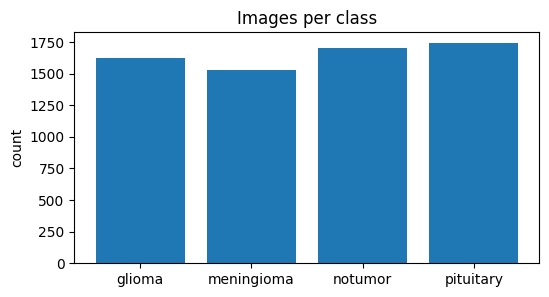

In [4]:
(X_tr, y_tr), (X_va, y_va), (_, y_te) = get_splits(spec)
counts = class_distribution(np.concatenate([y_tr, y_va, y_te]), CLASSES, "(full dataset, after dedup)")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts)
plt.title("Images per class")
plt.ylabel("count")
plt.show()

## 5. tf.data pipelines and run record

In [5]:
train_ds, val_ds, class_weight = get_datasets(spec, BATCH_SIZE, strategy=cfg.strategy)
run_dir = start_run(cfg, spec, name="mobilenetv2")
print("Run dir:", run_dir)


Class distribution (train)
  glioma         1134   24.5%  #####################################
  meningioma     1073   23.2%  ###################################
  notumor        1196   25.9%  #######################################
  pituitary      1218   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (val)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  #######################################
  pituitary       261   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (test, counts only)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  ###########################

I0000 00:00:1792682678.096583    2568 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11532 MB memory:  -> device: 0, name: NVIDIA TITAN Xp, pci bus id: 0000:84:00.0, compute capability: 6.1


Run dir: runs/20261022-152441_mobilenetv2_seed42


## 6. Sanity checks

In [6]:
for xb, yb in train_ds.take(1):
    print(xb.shape, xb.dtype, yb.shape)
    print("pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

2026-10-22 15:24:46.747359: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


(32, 224, 224, 3) <dtype: 'float32'> (32,)
pixel range: 0.0 - 1.0


2026-10-22 15:24:47.537156: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2026-10-22 15:24:54.850565: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


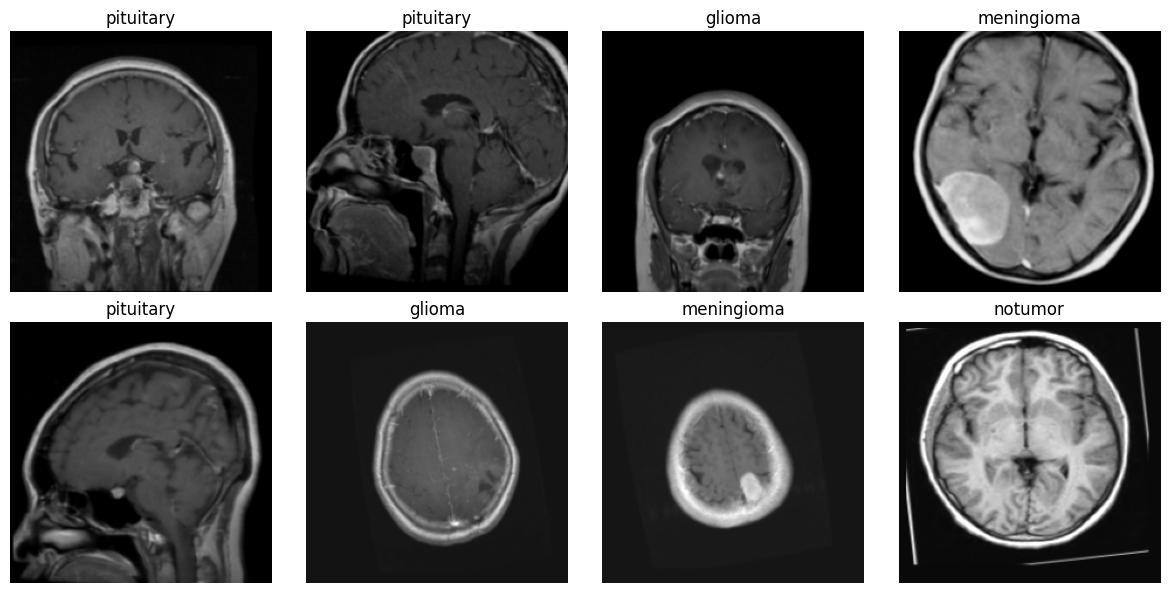

In [7]:
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(xb[i].numpy()[..., ::-1])   # BGR -> RGB for display
    plt.title(CLASSES[int(yb[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

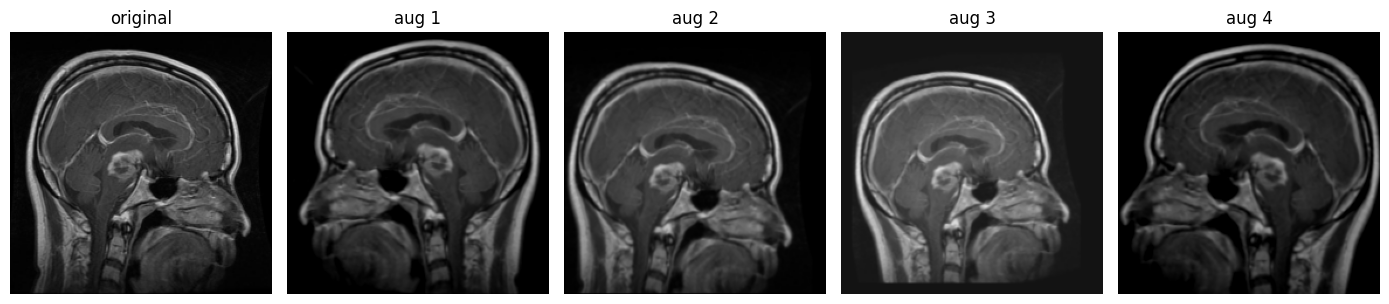

In [8]:
aug = build_augmenter(cfg.seed)
img = X_tr[:1].astype("float32")

plt.figure(figsize=(14, 3))
plt.subplot(1, 5, 1)
plt.imshow(X_tr[0][..., ::-1])
plt.title("original")
plt.axis("off")
for i in range(4):
    out = aug(img, training=True)[0].numpy().clip(0, 255).astype("uint8")
    plt.subplot(1, 5, i + 2)
    plt.imshow(out[..., ::-1])
    plt.title(f"aug {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build MobileNetV2

In [9]:
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.layers.Rescaling(2.0, offset=-1.0, name="to_minus1_1")(inputs)

base = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base.trainable = False
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(cfg.dropout)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mobilenetv2_mri")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step 


Model: "mobilenetv2_mri"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_minus1_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Training helpers

In [10]:
from src.EpochTimer import EpochTimer


def make_callbacks(tag):
    timer = EpochTimer()
    return timer, [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
        tf.keras.callbacks.ModelCheckpoint(str(run_dir / f"best_{tag}.keras"), monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.BackupAndRestore(backup_dir=str(run_dir / f"backup_{tag}")),
        timer,
    ]


def run_stage(tag, epochs, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    timer, callbacks = make_callbacks(tag)
    t0 = time.perf_counter()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=class_weight, callbacks=callbacks)
    total = time.perf_counter() - t0
    print(f"\n[{tag}] {len(timer.times)} epochs | {total:.1f} s | mean/epoch {np.mean(timer.times):.1f} s")
    return {"history": h.history, "epoch_times_s": timer.times, "total_s": total}


stages = {}

## 9. Stage 1: train the head (backbone frozen)

In [11]:
stages["head"] = run_stage("head", cfg.head_epochs, cfg.learning_rate)

Epoch 1/10


I0000 00:00:1792682748.025428    3081 cuda_dnn.cc:529] Loaded cuDNN version 90300


145/145 ━━━━━━━━━━━━━━━━━━━━ 100s 653ms/step - accuracy: 0.6521 - loss: 0.8505 - val_accuracy: 0.7885 - val_loss: 0.5764 - learning_rate: 0.0010
Epoch 2/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 92s 632ms/step - accuracy: 0.8453 - loss: 0.4137 - val_accuracy: 0.8340 - val_loss: 0.4560 - learning_rate: 0.0010
Epoch 3/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 617ms/step - accuracy: 0.8716 - loss: 0.3525 - val_accuracy: 0.7935 - val_loss: 0.5428 - learning_rate: 0.0010
Epoch 4/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 628ms/step - accuracy: 0.8794 - loss: 0.3108 - val_accuracy: 0.8289 - val_loss: 0.4478 - learning_rate: 0.0010
Epoch 5/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 619ms/step - accuracy: 0.8953 - loss: 0.2825 - val_accuracy: 0.8148 - val_loss: 0.4686 - learning_rate: 0.0010
Epoch 6/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 628ms/step - accuracy: 0.9042 - loss: 0.2685 - val_accuracy: 0.8451 - val_loss: 0.4135 - learning_rate: 0.0010
Epoch 7/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 623ms/step - accuracy: 0.9039 - loss

## 10. Stage 2: fine-tune the top backbone layers (low learning rate)

In [12]:
base.trainable = True
for layer in base.layers[:-cfg.finetune_layers]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
print("trainable backbone layers:", sum(l.trainable for l in base.layers), "of", len(base.layers))

stages["finetune"] = run_stage("finetune", cfg.finetune_epochs, cfg.finetune_lr)

# keep the best weights over BOTH stages (restore_best_weights only covers the last one)
best_tag = min(stages, key=lambda t: min(stages[t]["history"]["val_loss"]))
model = tf.keras.models.load_model(run_dir / f"best_{best_tag}.keras")
print("best stage by val loss:", best_tag)

(run_dir / "history.json").write_text(json.dumps(
    {"best_stage": best_tag, **stages}, indent=2, default=float,
))

trainable backbone layers: 19 of 154
Epoch 1/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 99s 646ms/step - accuracy: 0.9083 - loss: 0.2455 - val_accuracy: 0.8502 - val_loss: 0.4164 - learning_rate: 1.0000e-05
Epoch 2/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 629ms/step - accuracy: 0.9291 - loss: 0.2031 - val_accuracy: 0.8927 - val_loss: 0.2993 - learning_rate: 1.0000e-05
Epoch 3/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 629ms/step - accuracy: 0.9291 - loss: 0.1856 - val_accuracy: 0.8836 - val_loss: 0.3179 - learning_rate: 1.0000e-05
Epoch 4/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 93s 638ms/step - accuracy: 0.9329 - loss: 0.1768 - val_accuracy: 0.8998 - val_loss: 0.2980 - learning_rate: 1.0000e-05
Epoch 5/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 92s 634ms/step - accuracy: 0.9430 - loss: 0.1462 - val_accuracy: 0.8947 - val_loss: 0.2907 - learning_rate: 1.0000e-05
Epoch 6/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 623ms/step - accuracy: 0.9469 - loss: 0.1403 - val_accuracy: 0.8856 - val_loss: 0.2923 - learning_rate: 1.0000e-05
Epoch 7/1

4411

## 11. Training curves and fit analysis

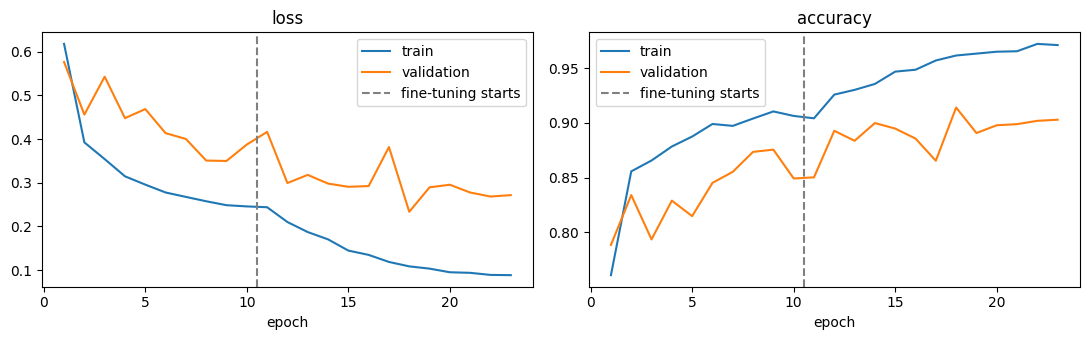

best epoch: 18 of 23 (finetune stage)
train acc  0.961 | val acc  0.914 | gap +0.048
train loss 0.108 | val loss 0.233 | gap +0.125
verdict: good fit: small gap between train and validation


In [13]:
head_h, ft_h = stages["head"]["history"], stages["finetune"]["history"]
h = {k: head_h[k] + ft_h[k] for k in head_h if k in ft_h}
n_head = len(head_h["loss"])
epochs = np.arange(1, len(h["loss"]) + 1)
best = int(np.argmin(h["val_loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ("loss", "accuracy")):
    a.plot(epochs, h[m], label="train")
    a.plot(epochs, h[f"val_{m}"], label="validation")
    a.axvline(n_head + 0.5, color="gray", linestyle="--", label="fine-tuning starts")
    a.set_title(m)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

tr_acc, va_acc = h["accuracy"][best], h["val_accuracy"][best]
tr_loss, va_loss = h["loss"][best], h["val_loss"][best]
acc_gap = tr_acc - va_acc
loss_gap = va_loss - tr_loss

print(f"best epoch: {best + 1} of {len(epochs)} ({'head' if best < n_head else 'finetune'} stage)")
print(f"train acc  {tr_acc:.3f} | val acc  {va_acc:.3f} | gap {acc_gap:+.3f}")
print(f"train loss {tr_loss:.3f} | val loss {va_loss:.3f} | gap {loss_gap:+.3f}")

if acc_gap > 0.10:
    verdict = "OVERFITTING: train accuracy is far above validation accuracy"
elif acc_gap > 0.05:
    verdict = "mild overfitting"
elif tr_acc < 0.85 and va_acc < 0.85:
    verdict = "possible UNDERFITTING: both accuracies are low, train longer or unfreeze more layers"
else:
    verdict = "good fit: small gap between train and validation"
print("verdict:", verdict)

## 12. Evaluate on validation

In [14]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.4f}")

31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.8627 - loss: 0.3738
val loss: 0.2334 | val accuracy: 0.9140


## 13. Per-class report
`val_ds` is not shuffled, so predictions and labels line up. Predictions are computed once and reused below.

2026-10-22 16:01:01.904220: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-22 16:01:03.876511: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


              precision    recall  f1-score   support

      glioma      0.954     0.848     0.898       243
  meningioma      0.833     0.852     0.842       229
     notumor      0.980     0.957     0.968       255
   pituitary      0.893     0.989     0.938       261

    accuracy                          0.914       988
   macro avg      0.915     0.911     0.912       988
weighted avg      0.916     0.914     0.914       988



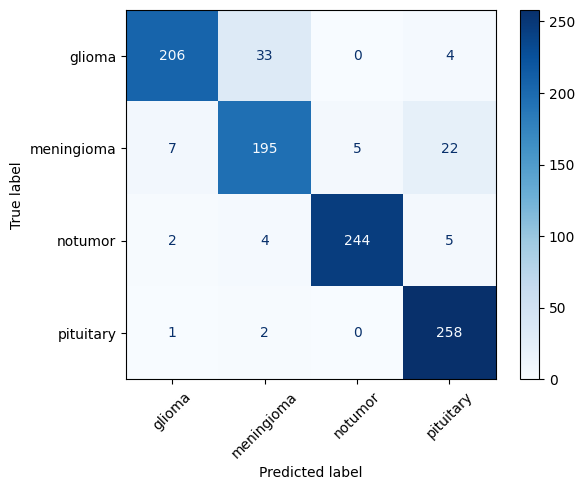

In [15]:
xs, ys = [], []
for xb, yb in val_ds:
    xs.append(xb.numpy())
    ys.append(yb.numpy())
X_val_img = np.concatenate(xs)
y_true = np.concatenate(ys)

probs = model.predict(X_val_img, batch_size=BATCH_SIZE, verbose=0)
y_pred = probs.argmax(axis=1)
conf = probs.max(axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred), display_labels=CLASSES
).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 14. Confusion analysis (validation only; the test set stays untouched)

85 misclassified of 988 (8.6%)
mean confidence: correct 0.960 | wrong 0.760
wrong predictions with confidence > 0.9: 17 of 85

Most frequent confusions (true -> predicted):
       glioma -> meningioma    33  (13.6% of all true glioma)
   meningioma -> pituitary     22  (9.6% of all true meningioma)
   meningioma -> glioma         7  (3.1% of all true meningioma)
      notumor -> pituitary      5  (2.0% of all true notumor)
   meningioma -> notumor        5  (2.2% of all true meningioma)
      notumor -> meningioma     4  (1.6% of all true notumor)

tumor predicted as 'notumor' (missed tumors): 5


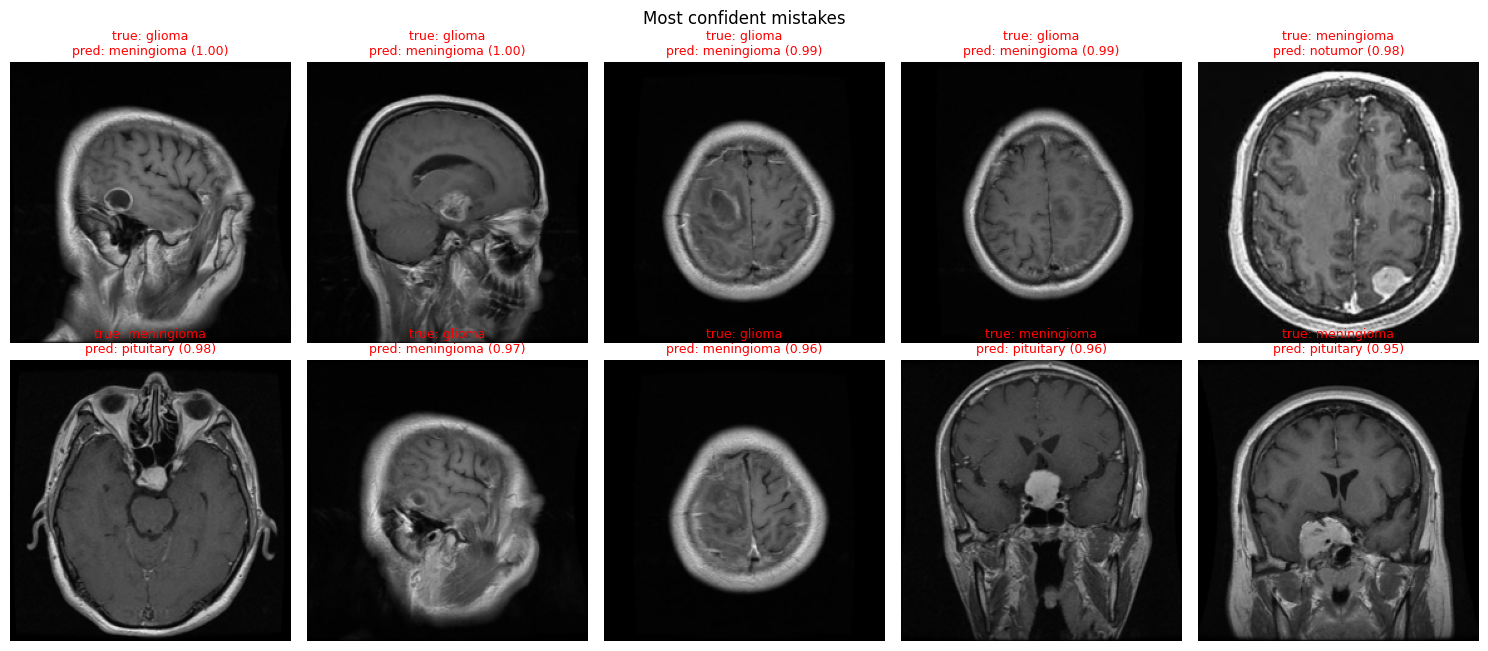

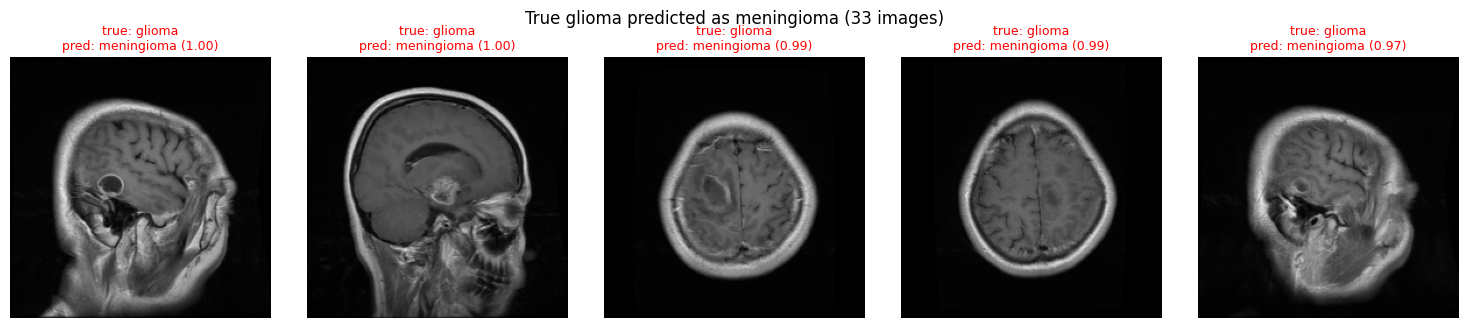

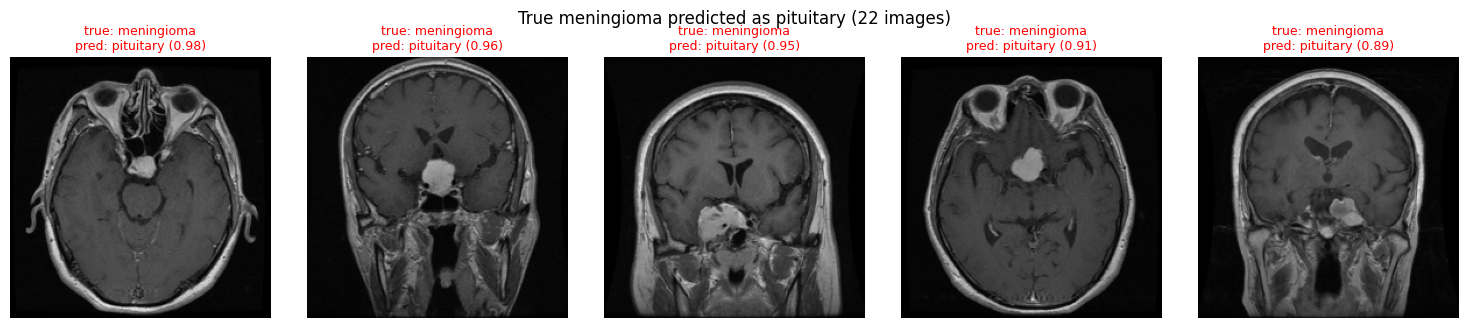

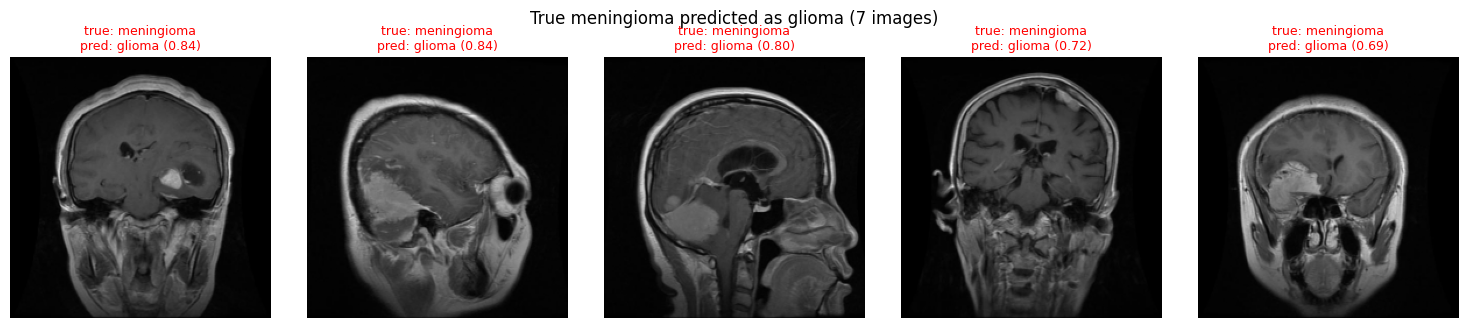

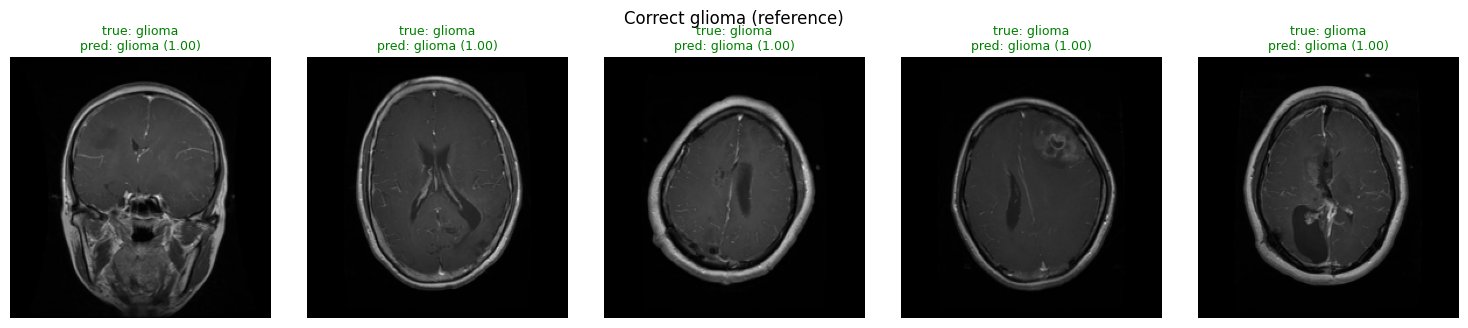

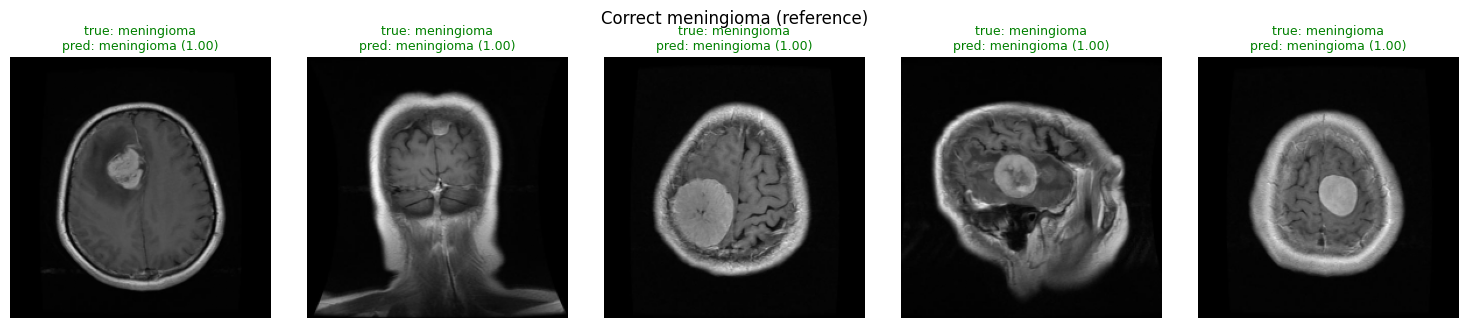

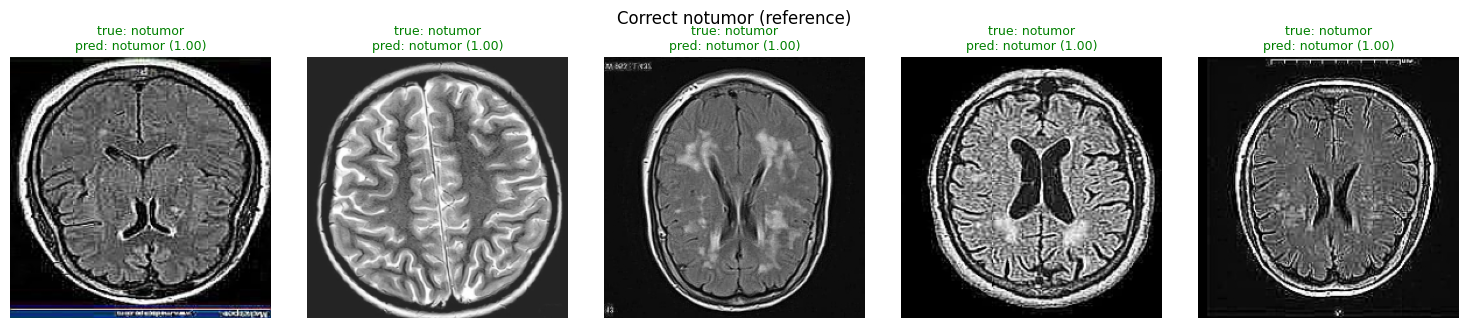

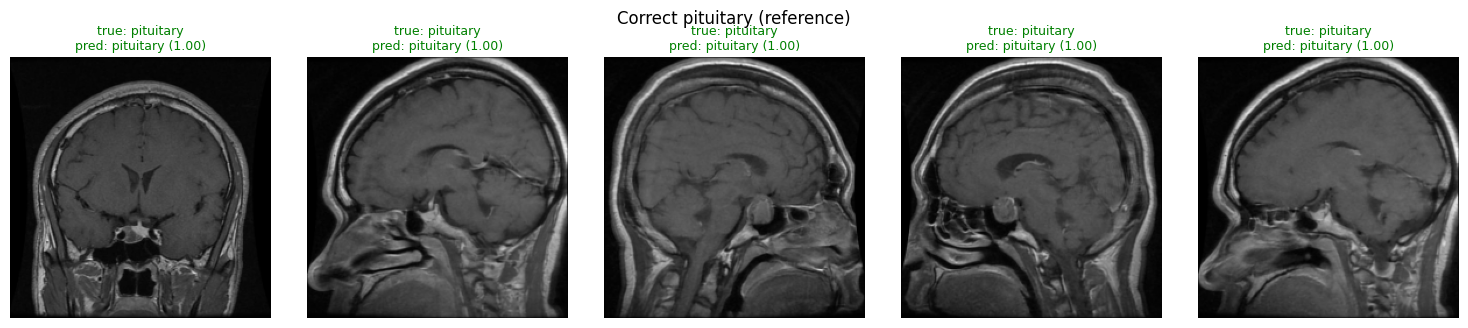

In [16]:
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]

print(f"{len(wrong)} misclassified of {len(y_true)} ({100 * len(wrong) / len(y_true):.1f}%)")
if len(wrong):
    print(f"mean confidence: correct {conf[right].mean():.3f} | wrong {conf[wrong].mean():.3f}")
    print(f"wrong predictions with confidence > 0.9: {(conf[wrong] > 0.9).sum()} of {len(wrong)}")

labels = list(range(len(CLASSES)))
cm = confusion_matrix(y_true, y_pred, labels=labels)
pairs = sorted(((cm[i, j], i, j) for i in labels for j in labels if i != j and cm[i, j] > 0), reverse=True)

print("\nMost frequent confusions (true -> predicted):")
for n, i, j in pairs[:6]:
    print(f"  {CLASSES[i]:>11} -> {CLASSES[j]:<11} {n:>4}  ({100 * n / cm[i].sum():.1f}% of all true {CLASSES[i]})")

missed = sum(cm[i, CLASSES.index("notumor")] for i in labels if CLASSES[i] != "notumor")
print(f"\ntumor predicted as 'notumor' (missed tumors): {missed}")


def show(idx, title, cols=5, max_n=10):
    idx = list(idx)[:max_n]
    if not idx:
        print(f"{title}: none")
        return
    rows = int(np.ceil(len(idx) / cols))
    plt.figure(figsize=(3 * cols, 3.3 * rows))
    for k, i in enumerate(idx):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(X_val_img[i][..., ::-1])
        ok = y_true[i] == y_pred[i]
        plt.title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})",
                  fontsize=9, color="green" if ok else "red")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show(wrong[np.argsort(-conf[wrong])], "Most confident mistakes")

for n, i, j in pairs[:3]:
    idx = np.where((y_true == i) & (y_pred == j))[0]
    show(idx[np.argsort(-conf[idx])], f"True {CLASSES[i]} predicted as {CLASSES[j]} ({n} images)", max_n=5)

for c in labels:
    idx = right[y_true[right] == c]
    show(idx[np.argsort(-conf[idx])], f"Correct {CLASSES[c]} (reference)", max_n=5)

## 15 Save model

In [17]:
from pathlib import Path

model_path = (run_dir / "model.keras").resolve()
model.save(model_path)
print(f"Model saved: {model_path}")


Model saved: /NeuroVision-AI/runs/20261022-152441_mobilenetv2_seed42/model.keras


## 16. Final test (run once)

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8828 - loss: 0.3090 
TEST loss: 0.2336 | TEST accuracy: 0.9140
              precision    recall  f1-score   support

      glioma      0.960     0.881     0.918       243
  meningioma      0.877     0.808     0.841       229
     notumor      0.976     0.961     0.968       255
   pituitary      0.855     0.992     0.918       261

    accuracy                          0.914       988
   macro avg      0.917     0.910     0.912       988
weighted avg      0.917     0.914     0.913       988



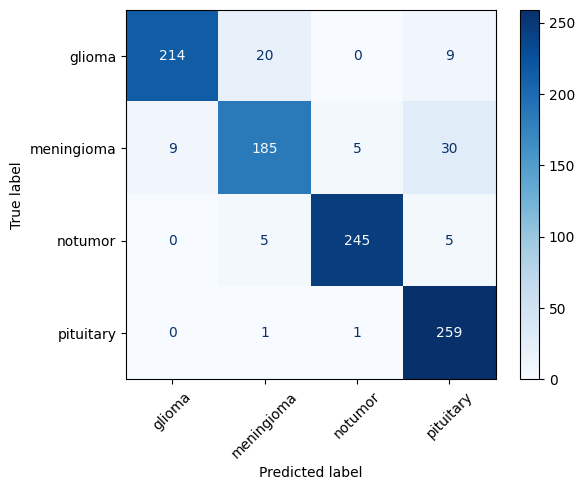

In [18]:
if "test_result" not in globals():
    test_ds = get_test_ds(spec, BATCH_SIZE)
    test_loss, test_acc = model.evaluate(test_ds)
    test_result = {
        "loss": float(test_loss),
        "accuracy": float(test_acc),
        "y_true": np.concatenate([yb.numpy() for _, yb in test_ds]),
        "y_pred": np.argmax(model.predict(test_ds, verbose=0), axis=1),
    }
    (run_dir / "test_result.json").write_text(
        json.dumps({"loss": test_result["loss"], "accuracy": test_result["accuracy"]}, indent=2)
    )
else:
    print("Test set already evaluated: showing the stored result, not evaluating again.")

print(f"TEST loss: {test_result['loss']:.4f} | TEST accuracy: {test_result['accuracy']:.4f}")
print(classification_report(test_result["y_true"], test_result["y_pred"], target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(
    confusion_matrix(test_result["y_true"], test_result["y_pred"]), display_labels=CLASSES
).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 17. Predict one image

data/raw/glioma/Te-gl_0151.jpg
{'label': 'glioma', 'confidence': 0.9973695278167725, 'probs': {'glioma': 0.9973695278167725, 'meningioma': 0.002592856530100107, 'notumor': 2.6903062462224625e-05, 'pituitary': 1.066145887307357e-05}, 'uncertain': False}


2026-10-22 16:01:20.643482: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


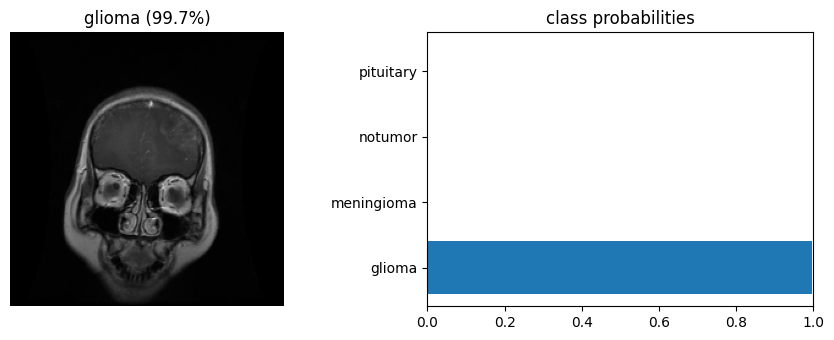

In [19]:
import importlib
import src.predict as sp
importlib.reload(sp)
from src.predict import predict_image, show_prediction

sample_dir = Path(RAW_DIR) / CLASSES[0]
sample = sorted(p for p in sample_dir.iterdir() if p.is_file())[151]
print(sample)

result = predict_image(sample, model, CLASSES)
print({k: v for k, v in result.items() if k != "image"})
show_prediction(result)